# Projet complet de classification d'images en PyTorch, brique par brique

Ce fichier est un notebook en "mode cellules" : chaque bloc `# %%` est une
cellule que VS Code execute comme dans Jupyter (Shift+Entree). Il suit
le fil du cours, en 13 etapes ; un commentaire `# === Etape N - nom ===`
ouvre chaque etape :

1 imports et reglages -> 2 importer et explorer -> 3 cataloguer -> 4 decouper
-> 5 pretraiter -> 6 augmenter -> 7 charger par lots -> 8 modele
-> 9 perte et optimiseur -> 10 entrainer -> 11 evaluer
-> 12 sauvegarder et exporter -> 13 predire

Trois ecarts par rapport a cet ordre, parce que le code en a besoin : la classe
Dataset (etape 7) est ecrite avant le calcul de mean / std (etape 5) qui s'en sert ;
le transfert (etape 8, suite) et l'export ONNX (etape 12, suite) sont a la fin,
car ils reutilisent la boucle fit et le modele entraine.

Il se lit de haut en bas et ne depend d'aucun autre fichier du projet.

In [1]:
# %% dossier_de_travail
import os                                   # os : outils du systeme, dont le dossier courant
from pathlib import Path                    # Path : chemins de fichiers
if Path.cwd().name == "notebooks":          # si Python tourne depuis le dossier notebooks...
    os.chdir(Path.cwd().parent)             # ...on remonte d'un cran, a la racine du projet
print(os.getcwd())                          # doit se terminer par pytorch_starter

c:\Users\Michaël\Documents\Dev\vision-livrables\projets\pytorch_starter


In [2]:
# === Etape 1 - Imports et reglages ===
# Les bonnes librairies, dans un ordre fixe (standard, tiers, projet).
from __future__ import annotations  # permet d'ecrire les types modernes (dict[str, int]) sans souci de version de Python

import copy  # copie complete d'un objet (ici : les poids du modele)
import hashlib  # empreintes de fichiers (md5) : deux fichiers identiques ont la meme empreinte
import random  # hasard de Python, fixe plus bas pour des resultats reproductibles
import time  # mesure du temps ecoule
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import matplotlib.pyplot as plt  # matplotlib : affichage d'images et de graphiques
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame), ici le catalogue des images
import torch  # PyTorch : tenseurs (tableaux de nombres, sur CPU ou GPU) et apprentissage profond
import torch.nn as nn  # nn : briques de reseau (couches, fonctions de perte)
from PIL import Image  # PIL (Pillow) : ouvrir les fichiers images
from sklearn.metrics import classification_report, confusion_matrix, f1_score  # rapport par classe, matrice de confusion, F1
from sklearn.model_selection import train_test_split  # coupe un tableau en deux parties (ex. entrainement / test)
from torch.utils.data import DataLoader, Dataset  # Dataset : donne une image a la fois ; DataLoader : les regroupe en lots
from torchvision import models  # modeles connus (ResNet...) avec poids pre-entraines
from torchvision.transforms import v2  # transformations d'images (redimensionner, retourner, normaliser...)

print("PyTorch", torch.__version__)  # version installee (utile si un resultat differe)

PyTorch 2.15.0+cpu


In [3]:
# Tous les reglages a un seul endroit. Dans la version scripts, ce bloc devient
# le fichier configs/default.yaml : rien d'autre ne change.
CONFIG = {  # dictionnaire des reglages
    "data_dir": "data/raw/neu_cls_flat",  # cas B : un sous-dossier par classe
    "output_dir": "outputs/notebook",  # dossier ou ecrire les resultats (split, modeles, courbes)
    "image_size": 128,  # cote des images donnees au reseau (128 x 128 pixels)
    "batch_size": 32,  # 32 images traitees ensemble a chaque pas (un lot / batch) : plus grand = plus rapide mais plus de memoire
    "num_workers": 0,  # 0 dans un notebook sous Windows (voir etape 7)
    "epochs": 15,  # nombre maximal d'epoques (une epoque = un passage complet sur les images d'entrainement)
    "learning_rate": 1e-3,  # taux d'apprentissage : taille du pas de chaque mise a jour des poids
    "weight_decay": 1e-4,  # pousse les poids vers 0 : limite l'apprentissage par coeur
    "patience": 4,  # arret anticipe : epoques sans amelioration tolerees
    "seed": 42,  # graine du hasard : memes resultats a chaque execution
    "val_fraction": 0.15,  # 15 % des images pour la validation (choisir les reglages)
    "test_fraction": 0.15,  # 15 % des images pour le test (note finale, une seule fois)
}
OUTPUT_DIR = Path(CONFIG["output_dir"])  # chemin du dossier de sortie
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # cree le dossier (et ses parents) s'il n'existe pas

In [4]:
def seed_everything(seed: int) -> None:  # fixe toutes les sources de hasard ; ne renvoie rien
    """Fixe toutes les graines : deux executions donnent les memes resultats."""
    random.seed(seed)  # hasard de Python
    np.random.seed(seed)  # hasard de numpy
    torch.manual_seed(seed)  # hasard de PyTorch sur CPU (poids initiaux, melange des lots)
    torch.cuda.manual_seed_all(seed)  # hasard de PyTorch sur GPU (sans effet s'il n'y en a pas)


seed_everything(CONFIG["seed"])  # applique la graine tout de suite
# Le meme code tourne sur CPU ou sur GPU : seul le device change.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # carte graphique (GPU) si elle existe, sinon processeur
print("Device :", DEVICE)  # affiche l'appareil utilise

Device : cpu


In [5]:
# %% dossier_de_travail
import os                                   # os : outils du systeme, dont le dossier courant
from pathlib import Path                    # Path : chemins de fichiers
if Path.cwd().name == "notebooks":          # si Python tourne depuis le dossier notebooks...
    os.chdir(Path.cwd().parent)             # ...on remonte d'un cran, a la racine du projet
print(os.getcwd())                          # doit se terminer par pytorch_starter
print(Path("data/raw/neu_cls_flat").exists())  # doit afficher True

c:\Users\Michaël\Documents\Dev\vision-livrables\projets\pytorch_starter
True


In [6]:
# === Etape 2 - Importer et explorer ===
# Regarder les donnees avant d'ecrire le moindre modele.
DATA_DIR = Path(CONFIG["data_dir"])  # dossier des images
EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png"}  # extensions de fichiers acceptees comme images

for class_dir in sorted(DATA_DIR.iterdir()):  # pour chaque sous-dossier (= une classe), trie pour un ordre stable
    n_images = sum(1 for p in class_dir.iterdir() if p.suffix.lower() in EXTENSIONS)  # compte les fichiers images du dossier
    print(f"{class_dir.name:12s} {n_images:5d} images")  # nom de la classe et nombre d'images, alignes en colonnes

crazing        300 images
inclusion      300 images
patches        300 images
pitted         300 images
rolled         300 images
scratches      300 images


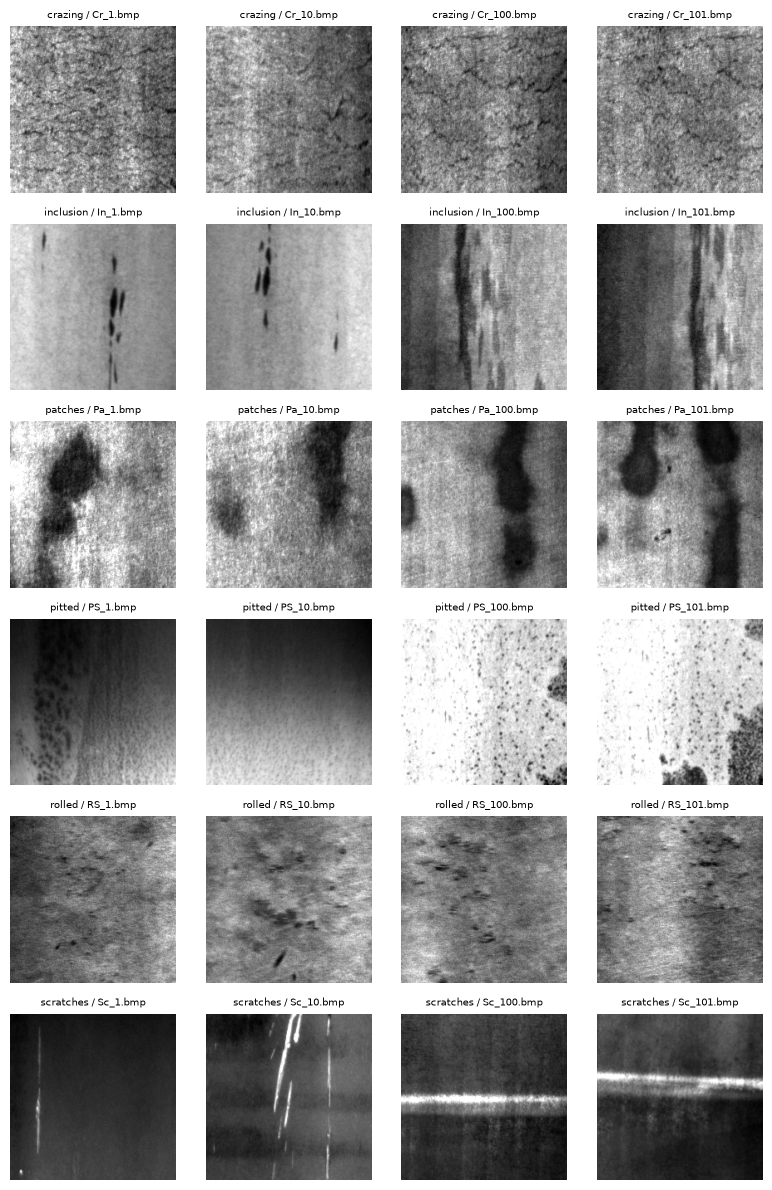

In [7]:
# Afficher quelques images par classe : c'est le controle le plus utile du projet.
class_names = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())  # noms des classes = noms des sous-dossiers, tries
fig, axes = plt.subplots(len(class_names), 4, figsize=(8, 2 * len(class_names)))  # grille : une ligne par classe, 4 colonnes
for row, name in enumerate(class_names):  # pour chaque classe (row : numero de ligne)
    paths = sorted(DATA_DIR.joinpath(name).glob("*.bmp"))[:4]  # les 4 premieres images .bmp de la classe
    for col, path in enumerate(paths):  # pour chacune (col : numero de colonne)
        axes[row, col].imshow(Image.open(path), cmap="gray")  # affiche l'image en niveaux de gris
        axes[row, col].set_title(f"{name} / {path.name}", fontsize=7)  # titre : classe / nom du fichier
        axes[row, col].axis("off")  # cache les axes gradues
plt.tight_layout()  # ajuste les marges
plt.show()  # affiche la figure

In [8]:
# Tailles, modes (L = niveaux de gris, RGB), fichiers illisibles ou tronques, doublons exacts.
sizes, modes, broken, hashes = {}, {}, [], {}  # compteurs de tailles et de modes, fichiers illisibles, empreintes -> fichiers
for path in sorted(DATA_DIR.rglob("*.bmp")):  # pour chaque image .bmp, dans tous les sous-dossiers
    try:  # on essaie d'ouvrir l'image ; si elle est abimee, on passe au except
        with Image.open(path) as image:  # ouvre l'image (et la referme automatiquement a la fin du bloc)
            sizes[image.size] = sizes.get(image.size, 0) + 1  # compte cette taille (largeur, hauteur)
            modes[image.mode] = modes.get(image.mode, 0) + 1  # compte ce mode de couleur
            image.load()  # lit tous les pixels : Image.open ne lit que l'en-tete, un fichier coupe en route passerait inapercu
    except OSError:  # si le fichier n'est pas une image lisible, ou s'il est tronque
        broken.append(path)  # on le note
    digest = hashlib.md5(path.read_bytes()).hexdigest()  # empreinte md5 du contenu du fichier
    hashes.setdefault(digest, []).append(path)  # range le fichier sous son empreinte
duplicates = [paths for paths in hashes.values() if len(paths) > 1]  # groupes de fichiers a contenu identique
print("Tailles :", sizes)  # tailles rencontrees et leur nombre
print("Modes   :", modes)  # modes rencontres et leur nombre
print("Illisibles :", len(broken))  # nombre de fichiers illisibles
print("Doublons exacts :", [[p.name for p in group] for group in duplicates])  # noms des fichiers en double

Tailles : {(200, 200): 1800}
Modes   : {'L': 1800}
Illisibles : 0
Doublons exacts : [['Pa_101.bmp', 'Pa_105.bmp']]


In [ ]:
# === Etape 3 - Cataloguer ===
# Quel que soit le rangement d'origine, on construit le meme tableau
# (path, label). Toute la suite ne lit que ce tableau.
def catalog_from_class_folders(root: Path) -> pd.DataFrame:  # dossiers par classe -> tableau (path, label)
    """Cas B : root/<classe>/image.ext -> DataFrame (path, label)."""
    rows = [  # une ligne par image
        {"path": path.as_posix(), "label": class_dir.name}  # chemin ecrit avec des / (lisible partout) et classe (nom du dossier)
        for class_dir in sorted(root.iterdir())  # pour chaque element du dossier racine
        if class_dir.is_dir()  # seulement les sous-dossiers (= les classes)
        for path in sorted(class_dir.iterdir())  # pour chaque fichier du sous-dossier
        if path.suffix.lower() in EXTENSIONS  # seulement les fichiers images
    ]
    return pd.DataFrame(rows)  # le catalogue sous forme de tableau pandas


catalog = catalog_from_class_folders(DATA_DIR)  # construit le catalogue
class_names = sorted(catalog["label"].unique())  # liste triee des classes
class_to_idx = {name: i for i, name in enumerate(class_names)}  # nom de classe -> numero (le reseau ne manipule que des nombres)
print(catalog.head())  # les 5 premieres lignes
print(catalog["label"].value_counts())  # nombre d'images par classe

In [ ]:
def catalog_from_split_folders(root: Path) -> pd.DataFrame:  # dossiers train/val/test -> tableau (path, label, split)
    """Cas A : root/{train,val,test}/<classe>/image.ext ; le decoupage est conserve."""
    frames = []  # un tableau par partie
    for subset in ("train", "val", "test"):  # pour chaque partie deja faite
        frame = catalog_from_class_folders(root / subset)  # catalogue de cette partie
        frame["split"] = subset  # note de quelle partie il vient
        frames.append(frame)  # le garde
    return pd.concat(frames, ignore_index=True)  # colle les trois tableaux, lignes renumerotees


def catalog_from_csv(images_dir: Path, csv_path: Path) -> pd.DataFrame:  # dossier d'images + CSV -> tableau (path, label)
    """Cas C : un dossier d'images et un CSV (filename, label)."""
    table = pd.read_csv(csv_path)  # lit le CSV des etiquettes
    return pd.DataFrame({"path": [(images_dir / f).as_posix() for f in table["filename"]], "label": table["label"]})  # chemin + classe


catalog_a = catalog_from_split_folders(Path("data/raw/neu_cls_split"))  # meme jeu range en train/val/test
catalog_c = catalog_from_csv(Path("data/raw/neu_cls_csv/images"), Path("data/raw/neu_cls_csv/labels.csv"))  # meme jeu avec un CSV
print("Cas A :", len(catalog_a), "images, decoupage fourni :", catalog_a["split"].value_counts().to_dict())  # verifie le cas A
print("Cas C :", len(catalog_c), "images, memes classes :", sorted(catalog_c["label"].unique()) == class_names)  # verifie le cas C

In [ ]:
# === Etape 4 - Decouper ===
# Decoupage stratifie, graine fixe, enregistre en CSV, controle.
def make_split(catalog: pd.DataFrame, val_fraction: float, test_fraction: float, seed: int) -> pd.DataFrame:  # renvoie le catalogue + split
    """Ajoute une colonne split (train / val / test), stratifiee par label."""
    # met de cote le test ; stratify garde les memes proportions de classes dans chaque partie
    train_val, test = train_test_split(catalog, test_size=test_fraction, stratify=catalog["label"], random_state=seed)
    # La fraction de validation est relative a ce qui reste apres le test.
    train, val = train_test_split(train_val, test_size=val_fraction / (1 - test_fraction), stratify=train_val["label"], random_state=seed)
    catalog = catalog.copy()  # copie : on ne modifie pas le tableau recu
    catalog.loc[train.index, "split"] = "train"  # marque les images d'entrainement
    catalog.loc[val.index, "split"] = "val"  # marque les images de validation
    catalog.loc[test.index, "split"] = "test"  # marque les images de test
    return catalog  # le catalogue avec sa colonne split


catalog = make_split(catalog, CONFIG["val_fraction"], CONFIG["test_fraction"], CONFIG["seed"])  # decoupe
catalog.to_csv(OUTPUT_DIR / "split.csv", index=False)  # sauvegarde le decoupage : il sert de reference ensuite
print(pd.crosstab(catalog["label"], catalog["split"]))  # nombre d'images par classe et par partie

In [ ]:
# Un chemin ne doit apparaitre que dans un seul sous-ensemble.
assert catalog["path"].is_unique, "des images apparaissent deux fois"  # arrete tout si un chemin est en double
assert set(catalog["split"]) == {"train", "val", "test"}  # les trois parties existent, et rien d'autre
catalog = pd.read_csv(OUTPUT_DIR / "split.csv")  # a partir d'ici, tout le monde relit ce fichier
train_df = catalog[catalog["split"] == "train"].reset_index(drop=True)  # images d'entrainement, numerotees a partir de 0
val_df = catalog[catalog["split"] == "val"].reset_index(drop=True)  # images de validation
test_df = catalog[catalog["split"] == "test"].reset_index(drop=True)  # images de test
print(len(train_df), len(val_df), len(test_df))  # taille de chaque partie

In [ ]:
# === Etape 7 - Charger par lots ===
# (en avance sur le fil : le calcul de mean / std de l'etape 5, juste apres, a besoin de cette classe)
# Le Dataset. Trois methodes, et le travail se fait dans __getitem__.
class ImageDataset(Dataset):  # jeu de donnees PyTorch : renvoie une image (transformee) et son numero de classe
    """Lit une image et son etiquette a partir du catalogue."""

    def __init__(self, frame: pd.DataFrame, class_to_idx: dict[str, int], transform=None) -> None:  # tableau, classes, transformation
        self.paths = frame["path"].tolist()  # liste des chemins
        self.targets = [class_to_idx[label] for label in frame["label"]]  # liste des numeros de classe, dans le meme ordre
        self.transform = transform  # transformation a appliquer (None = aucune)

    def __len__(self) -> int:  # nombre d'images du jeu (utilise par le DataLoader)
        return len(self.paths)  # une image par chemin

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:  # renvoie (image, classe) numero index
        # convert("RGB") rend le pipeline identique pour des images grises ou couleur.
        image = Image.open(self.paths[index]).convert("RGB")  # ouvre l'image, 3 canaux
        if self.transform is not None:  # si une transformation est fournie
            image = self.transform(image)  # l'applique (l'image devient un tenseur)
        return image, self.targets[index]  # l'image et son numero de classe


raw_dataset = ImageDataset(train_df, class_to_idx)  # jeu sans transformation : renvoie des images PIL
image, target = raw_dataset[0]  # premier element (appelle __getitem__(0))
print(type(image), image.size, image.mode, "->", target, class_names[target])  # type, taille, mode, numero et nom de classe

In [ ]:
# === Etape 5 - Pretraiter ===
# Statistiques de normalisation, calculees sur le train seulement.
def compute_mean_std(frame: pd.DataFrame, image_size: int) -> tuple[list[float], list[float]]:  # renvoie (moyennes, ecarts-types)
    """Moyenne et ecart-type par canal, sur des images en [0, 1]."""
    # tenseur, redimensionnement, valeurs 0-1 (pas encore de normalisation, puisqu'on la calcule)
    to_tensor = v2.Compose([v2.ToImage(), v2.Resize((image_size, image_size), antialias=True), v2.ToDtype(torch.float32, scale=True)])
    dataset = ImageDataset(frame, class_to_idx, to_tensor)  # jeu avec cette transformation
    total, total_sq, n_pixels = torch.zeros(3), torch.zeros(3), 0  # sommes par canal, sommes des carres, nombre de pixels
    for i in range(len(dataset)):  # pour chaque image
        image, _ = dataset[i]  # image (3, H, W) ; la classe ne sert pas
        total += image.sum(dim=(1, 2))  # somme des valeurs de chaque canal
        total_sq += (image**2).sum(dim=(1, 2))  # somme des carres de chaque canal
        n_pixels += image.shape[1] * image.shape[2]  # nombre de pixels de l'image (H x W)
    mean = total / n_pixels  # moyenne par canal
    std = (total_sq / n_pixels - mean**2).sqrt()  # ecart-type par canal : racine de (moyenne des carres - carre de la moyenne)
    return mean.tolist(), std.tolist()  # en listes Python (faciles a sauvegarder)


MEAN, STD = compute_mean_std(train_df, CONFIG["image_size"])  # calcule sur le train seulement (le test ne doit rien influencer)
print("mean", [round(m, 4) for m in MEAN], "std", [round(s, 4) for s in STD])  # affiche, arrondi

In [ ]:
# === Etape 6 - Augmenter ===
# Cette cellule reunit deux etapes : ToImage, Resize, ToDtype et Normalize sont le pretraitement (etape 5, partout),
# les deux retournements aleatoires sont l'augmentation (etape 6, train seulement).
# Deux pipelines : augmentations a l'entrainement seulement, normalisation partout.
SIZE = (CONFIG["image_size"], CONFIG["image_size"])  # taille cible (hauteur, largeur)
train_transform = v2.Compose(  # transformations de l'entrainement, dans l'ordre
    [  # liste des etapes
        v2.ToImage(),  # PIL -> tenseur uint8 (C, H, W)
        v2.Resize(SIZE, antialias=True),  # toutes les images a la meme taille (antialias : lisse les escaliers)
        v2.RandomHorizontalFlip(p=0.5),  # valable ici : un defaut retourne reste le meme defaut
        v2.RandomVerticalFlip(p=0.5),  # augmentation : retourne haut-bas une fois sur deux
        v2.ToDtype(torch.float32, scale=True),  # uint8 [0, 255] -> float32 [0, 1]
        v2.Normalize(mean=MEAN, std=STD),  # normalisation : (valeur - moyenne) / ecart-type par canal
    ]
)
eval_transform = v2.Compose(  # transformations de validation / test : sans augmentation aleatoire
    [  # liste des etapes
        v2.ToImage(),  # PIL -> tenseur
        v2.Resize(SIZE, antialias=True),  # meme taille
        v2.ToDtype(torch.float32, scale=True),  # valeurs 0-1
        v2.Normalize(mean=MEAN, std=STD),  # meme normalisation (calculee sur le train)
    ]
)
train_dataset = ImageDataset(train_df, class_to_idx, train_transform)  # jeu d'entrainement, avec augmentation
val_dataset = ImageDataset(val_df, class_to_idx, eval_transform)  # jeu de validation
test_dataset = ImageDataset(test_df, class_to_idx, eval_transform)  # jeu de test
image, target = train_dataset[0]  # premier element, transforme
print(image.shape, image.dtype, image.min().item(), image.max().item())  # forme (3, 128, 128), type, min et max apres normalisation

In [ ]:
# === Etape 7 - Charger par lots (suite) ===
# Le DataLoader fabrique les lots. shuffle=True seulement pour le train.
# entrainement : melange a chaque epoque ; drop_last jette le dernier lot incomplet
train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True, num_workers=CONFIG["num_workers"], drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=CONFIG["num_workers"])  # ordre fixe
test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=CONFIG["num_workers"])  # ordre fixe
images, targets = next(iter(train_loader))  # un premier lot
print("lot :", images.shape, images.dtype, "| cibles :", targets.shape, targets.dtype)  # (32, 3, 128, 128) et (32,)

In [ ]:
# Etape 7 - Charger par lots : regarder ce que le reseau recoit vraiment (apres les transformations).
def show_batch(images: torch.Tensor, targets: torch.Tensor, class_names: list[str], n: int = 8) -> None:  # affiche ; ne renvoie rien
    """Affiche les n premieres images d'un lot normalise."""
    mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)  # moyenne et ecart-type en forme (3, 1, 1)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.4))  # n cases cote a cote
    for ax, image, target in zip(axes, images[:n], targets[:n]):  # pour chacune des n premieres images
        image = (image * std + mean).clamp(0, 1)  # on annule la normalisation pour l'affichage
        ax.imshow(image.permute(1, 2, 0))  # CHW -> HWC pour matplotlib
        ax.set_title(class_names[target], fontsize=8)  # titre : la classe
        ax.axis("off")  # cache les axes
    plt.tight_layout()  # ajuste les marges
    plt.show()  # affiche


show_batch(images, targets, class_names)  # montre le premier lot

In [ ]:
# Etape 7 - Charger par lots : desequilibre des classes. Ici les classes sont equilibrees (300 chacune),
# mais le code reste le meme : poids inverses aux effectifs, donnes a la perte.
counts = train_df["label"].value_counts().reindex(class_names).to_numpy()  # nombre d'images par classe, dans l'ordre des classes
class_weights = torch.tensor(len(train_df) / (len(class_names) * counts), dtype=torch.float32)  # classe rare -> poids plus grand
print(dict(zip(class_names, class_weights.round(decimals=3).tolist())))  # poids de chaque classe (1.0 si equilibre)

In [ ]:
# === Etape 8 - Modele ===
# Un reseau entierement connecte. Il ignore la structure 2D de l'image.
class MLP(nn.Module):  # perceptron multicouche : chaque pixel relie a chaque neurone
    """Flatten -> Linear -> ReLU -> Linear."""

    def __init__(self, image_size: int, num_classes: int, hidden: int = 256) -> None:  # taille d'image, nb de classes, neurones caches
        super().__init__()  # initialise la partie nn.Module (obligatoire)
        self.net = nn.Sequential(  # les couches, dans l'ordre
            nn.Flatten(),  # (N, 3, H, W) -> (N, 3*H*W)
            nn.Linear(3 * image_size * image_size, hidden),  # couche lineaire : chaque sortie = somme ponderee de toutes les entrees
            nn.ReLU(),  # activation ReLU : garde les valeurs positives, met 0 sinon
            nn.Dropout(0.3),  # eteint 30 % des valeurs au hasard pendant l'entrainement (contre le par-coeur)
            nn.Linear(hidden, num_classes),  # sortie = logits, un par classe
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # passage avant : lot d'images -> logits (scores bruts par classe)
        return self.net(x)  # applique les couches


mlp = MLP(CONFIG["image_size"], len(class_names))  # cree le MLP
print(mlp(images).shape, "| parametres :", sum(p.numel() for p in mlp.parameters()))  # forme de sortie et nombre de poids (enorme)

In [ ]:
# Etape 8 - Modele : un CNN classique, fait de blocs identiques.
class ConvBlock(nn.Module):  # un bloc de base du CNN (reseau convolutif)
    """Conv 3x3 -> BatchNorm -> ReLU -> MaxPool 2x2 : la taille spatiale est divisee par 2."""

    def __init__(self, in_channels: int, out_channels: int) -> None:  # canaux en entree et en sortie
        super().__init__()  # initialise la partie nn.Module
        self.block = nn.Sequential(  # les couches, dans l'ordre
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),  # convolution 3x3 : filtres de motifs locaux
            nn.BatchNorm2d(out_channels),  # BatchNorm : remet les valeurs a une echelle stable
            nn.ReLU(inplace=True),  # ReLU : garde le positif, met 0 sinon
            nn.MaxPool2d(2),  # garde le max de chaque carre 2x2 : hauteur et largeur divisees par 2
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # passage avant du bloc
        return self.block(x)  # applique les couches


class SimpleCNN(nn.Module):  # le CNN complet : blocs de convolution puis classifieur
    """4 blocs de convolution, puis moyenne spatiale et une couche de classification."""

    def __init__(self, num_classes: int, channels: tuple[int, ...] = (32, 64, 128, 256)) -> None:  # nb de classes, canaux des blocs
        super().__init__()  # initialise la partie nn.Module
        blocks, in_channels = [], 3  # blocs a construire ; l'image a 3 canaux
        for out_channels in channels:  # pour chaque nombre de canaux voulu
            blocks.append(ConvBlock(in_channels, out_channels))  # ajoute un bloc
            in_channels = out_channels  # la sortie devient l'entree du bloc suivant
        self.features = nn.Sequential(*blocks)  # extracteur de caracteristiques : les blocs a la suite
        self.pool = nn.AdaptiveAvgPool2d(1)  # (N, C, h, w) -> (N, C, 1, 1), quelle que soit la taille
        # aplatit en (N, C), dropout, puis une couche lineaire : un score par classe
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(in_channels, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # passage avant : image -> logits
        return self.classifier(self.pool(self.features(x)))  # caracteristiques -> moyenne -> classifieur

In [ ]:
# Etape 8 - Modele : tester avec un tenseur factice avant d'entrainer.
model = SimpleCNN(num_classes=len(class_names))  # cree le CNN
dummy = torch.zeros(2, 3, CONFIG["image_size"], CONFIG["image_size"])  # 2 images factices remplies de 0
with torch.no_grad():  # pas de gradient : simple verification
    print("features :", model.features(dummy).shape)  # sortie des blocs : (2, 256, 8, 8)
    print("sortie   :", model(dummy).shape)  # sortie du modele : (2, nb de classes)
print("parametres entrainables :", sum(p.numel() for p in model.parameters() if p.requires_grad))  # nombre de poids a apprendre

In [ ]:
from torchinfo import summary  # torchinfo : affiche un resume couche par couche d'un modele

# tableau : forme de sortie et nombre de poids de chaque couche (depth=2 : deux niveaux de detail)
summary(model, input_size=(1, 3, CONFIG["image_size"], CONFIG["image_size"]), depth=2, col_names=("output_size", "num_params"))

In [ ]:
# === Etape 9 - Perte et optimiseur ===
# Les trois objets dont la boucle a besoin : le modele sur son appareil, la perte (criterion), l'optimiseur.
model = SimpleCNN(num_classes=len(class_names)).to(DEVICE)  # modele neuf, sur CPU ou GPU
criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))  # attend des logits et des entiers
# optimiseur AdamW : met a jour les poids a partir des gradients, avec le taux et le weight decay de la config
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"])

# === Etape 10 - Entrainer ===
# Un pas d'entrainement = les cinq lignes centrales de PyTorch.
images, targets = images.to(DEVICE), targets.to(DEVICE)  # le lot sur le meme appareil que le modele
optimizer.zero_grad()  # 1. remettre les gradients a zero (ils s'accumulent sinon)
logits = model(images)  # 2. passage avant
loss = criterion(logits, targets)  # 3. perte
loss.backward()  # 4. gradients
optimizer.step()  # 5. mise a jour des poids
print("perte apres une etape :", round(loss.item(), 4))  # .item() : la perte en nombre Python

In [ ]:
# Test 1 : au depart, le modele devine au hasard, la perte doit valoir environ ln(nb classes).
model = SimpleCNN(num_classes=len(class_names)).to(DEVICE)  # modele neuf (poids au hasard)
model.eval()  # mode evaluation : dropout coupe
with torch.no_grad():  # pas de gradient
    initial_loss = criterion(model(images), targets).item()  # perte du modele non entraine
print(f"perte initiale {initial_loss:.3f} | attendu ln({len(class_names)}) = {np.log(len(class_names)):.3f}")  # valeurs proches attendues

In [ ]:
# Test 2 : le modele doit pouvoir apprendre par coeur un seul lot (perte proche de 0).
model = SimpleCNN(num_classes=len(class_names)).to(DEVICE)  # modele neuf
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["learning_rate"])  # son optimiseur
model.train()  # mode entrainement
for step in range(60):  # 60 pas sur le MEME lot
    optimizer.zero_grad()  # gradients a zero
    loss = criterion(model(images), targets)  # passage avant et perte
    loss.backward()  # gradients
    optimizer.step()  # mise a jour
    if step % 20 == 0 or step == 59:  # affiche de temps en temps et au dernier pas
        print(f"etape {step:2d} | perte {loss.item():.4f}")  # la perte doit descendre vers 0

In [ ]:
# Etape 10 - Entrainer : une epoque d'entrainement et une evaluation, sous forme de fonctions.
def train_one_epoch(model, loader, criterion, optimizer, device) -> tuple[float, float]:  # entraine une epoque
    """Une passe sur le train ; renvoie (perte moyenne, accuracy)."""
    model.train()  # mode entrainement : dropout et BatchNorm actifs
    total_loss, correct, seen = 0.0, 0, 0  # cumul de la perte, bonnes reponses, images vues
    for images, targets in loader:  # pour chaque lot
        images, targets = images.to(device), targets.to(device)  # sur l'appareil du modele
        optimizer.zero_grad()  # 1. gradients a zero
        logits = model(images)  # 2. passage avant
        loss = criterion(logits, targets)  # 3. perte
        loss.backward()  # 4. gradients
        optimizer.step()  # 5. mise a jour des poids
        total_loss += loss.item() * len(targets)  # .item() : un float, pas un tenseur avec son graphe
        correct += (logits.argmax(dim=1) == targets).sum().item()  # classe predite = score le plus haut ; compte les bonnes
        seen += len(targets)  # compte les images
    return total_loss / seen, correct / seen  # perte moyenne et accuracy (part de bonnes reponses)


@torch.no_grad()  # pas de gradients : plus rapide, moins de memoire
def evaluate(model, loader, criterion, device) -> tuple[float, float, np.ndarray, np.ndarray]:  # evalue sans apprendre
    """Une passe sans apprentissage ; renvoie perte, accuracy, predictions, cibles."""
    model.eval()  # BatchNorm et Dropout en mode evaluation
    total_loss, all_preds, all_targets = 0.0, [], []  # cumul de la perte, predictions et cibles de chaque lot
    for images, targets in loader:  # pour chaque lot
        images, targets = images.to(device), targets.to(device)  # sur l'appareil du modele
        logits = model(images)  # passage avant
        total_loss += criterion(logits, targets).item() * len(targets)  # ajoute la perte du lot
        all_preds.append(logits.argmax(dim=1).cpu())  # classes predites, ramenees sur CPU
        all_targets.append(targets.cpu())  # vraies classes
    preds, targets = torch.cat(all_preds).numpy(), torch.cat(all_targets).numpy()  # tous les lots en un tableau numpy
    return total_loss / len(targets), float((preds == targets).mean()), preds, targets  # perte, accuracy, predictions, cibles

In [ ]:
# boucle d'entrainement complete ; renvoie l'historique (un tableau, une ligne par epoque)
def fit(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs, patience, device, checkpoint_path):
    """Boucle complete : meilleur modele selon la validation, arret anticipe, historique."""
    history, best_val_loss, epochs_without_improvement = [], float("inf"), 0  # historique, meilleure perte de val, compteur
    for epoch in range(1, epochs + 1):  # pour chaque epoque, numerotees a partir de 1
        start = time.time()  # heure de debut de l'epoque
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)  # apprend
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)  # mesure sur la validation
        scheduler.step(val_loss)  # ReduceLROnPlateau regarde la perte de validation
        # garde les chiffres de l'epoque
        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc, "val_loss": val_loss, "val_acc": val_acc})
        improved = val_loss < best_val_loss  # True si la validation s'ameliore
        if improved:  # si nouveau record
            best_val_loss, epochs_without_improvement = val_loss, 0  # retient le record, remet le compteur a 0
            # sauvegarde une copie des poids (checkpoint = point de sauvegarde) et le numero d'epoque
            torch.save({"model_state": copy.deepcopy(model.state_dict()), "epoch": epoch}, checkpoint_path)
        else:  # pas d'amelioration
            epochs_without_improvement += 1  # une epoque de plus sans progres
        lr = optimizer.param_groups[0]["lr"]  # taux d'apprentissage actuel (le scheduler a pu le baisser)
        print(  # une ligne de suivi par epoque
            f"epoque {epoch:2d} | train perte {train_loss:.4f} acc {train_acc:.3f} | "
            # suite du texte : validation, taux d'apprentissage, duree, et " | meilleur" si record
            f"val perte {val_loss:.4f} acc {val_acc:.3f} | lr {lr:.1e} | {time.time() - start:.0f}s" + (" | meilleur" if improved else "")
        )
        if epochs_without_improvement >= patience:  # si la patience est epuisee
            print(f"arret anticipe : {patience} epoques sans amelioration")  # on previent
            break  # on arrete : continuer ferait apprendre par coeur
    return pd.DataFrame(history)  # l'historique en tableau


# Etape 9 (rappel) : la perte, l'optimiseur et le scheduler sont recrees ici, juste avant de lancer la boucle.
seed_everything(CONFIG["seed"])  # meme point de depart a chaque execution
model = SimpleCNN(num_classes=len(class_names)).to(DEVICE)  # modele neuf
criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))  # perte de classification ponderee par classe
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"])  # optimiseur
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)  # divise lr par 2 si val stagne 2 epoques
history = fit(  # lance l'entrainement
    model,  # le modele
    train_loader,  # lots d'entrainement
    val_loader,  # lots de validation
    criterion,  # la perte
    optimizer,  # l'optimiseur
    scheduler,  # le scheduler (regle le taux d'apprentissage)
    CONFIG["epochs"],  # nombre maximal d'epoques
    CONFIG["patience"],  # patience de l'arret anticipe
    DEVICE,  # CPU ou GPU
    OUTPUT_DIR / "cnn_best.pt",  # fichier du meilleur modele
)
history.to_csv(OUTPUT_DIR / "cnn_history.csv", index=False)  # sauvegarde l'historique

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))  # deux graphiques cote a cote
axes[0].plot(history["epoch"], history["train_loss"], label="train")  # perte d'entrainement par epoque
axes[0].plot(history["epoch"], history["val_loss"], label="val")  # perte de validation par epoque
axes[0].set_title("Perte")  # titre du graphique de gauche
axes[1].plot(history["epoch"], history["train_acc"], label="train")  # accuracy d'entrainement
axes[1].plot(history["epoch"], history["val_acc"], label="val")  # accuracy de validation
axes[1].set_title("Accuracy")  # titre du graphique de droite
for ax in axes:  # pour chaque graphique
    ax.set_xlabel("epoque")  # nom de l'axe horizontal
    ax.legend()  # legende
    ax.grid(alpha=0.3)  # quadrillage leger
plt.tight_layout()  # ajuste les marges
plt.show()  # affiche

In [ ]:
# === Etape 11 - Evaluer ===
# Le test, une seule fois, avec le meilleur checkpoint.
checkpoint = torch.load(OUTPUT_DIR / "cnn_best.pt", map_location=DEVICE, weights_only=True)  # relit le meilleur point de sauvegarde
model.load_state_dict(checkpoint["model_state"])  # remet ses poids dans le modele
test_loss, test_acc, preds, targets = evaluate(model, test_loader, criterion, DEVICE)  # note sur le test, jamais vu avant
print(f"meilleure epoque {checkpoint['epoch']} | test perte {test_loss:.4f} | accuracy {test_acc:.3f}")  # resume
print(f"F1 macro {f1_score(targets, preds, average='macro'):.3f}")  # F1 macro : moyenne simple des F1 de chaque classe
print(classification_report(targets, preds, target_names=class_names, digits=3))  # precision, rappel, F1 pour chaque classe

In [ ]:
matrix = confusion_matrix(targets, preds)  # matrice de confusion : ligne = vraie classe, colonne = classe predite
fig, ax = plt.subplots(figsize=(5.5, 5))  # un graphique
ax.imshow(matrix, cmap="Blues")  # dessine la matrice (plus fonce = plus d'images)
ax.set_xticks(range(len(class_names)), class_names, rotation=45, ha="right")  # noms des classes en colonnes, inclines
ax.set_yticks(range(len(class_names)), class_names)  # noms des classes en lignes
ax.set_xlabel("prediction")  # nom de l'axe horizontal
ax.set_ylabel("verite")  # nom de l'axe vertical
for i in range(len(class_names)):  # pour chaque ligne
    for j in range(len(class_names)):  # pour chaque colonne
        # ecrit le nombre dans la case : en blanc sur les cases foncees, en noir sinon
        ax.text(j, i, matrix[i, j], ha="center", va="center", color="white" if matrix[i, j] > matrix.max() / 2 else "black")
plt.tight_layout()  # ajuste les marges
plt.show()  # affiche

In [ ]:
# Regarder les erreurs une par une : souvent une etiquette fausse ou un cas limite.
errors = np.where(preds != targets)[0]  # positions des images mal classees
print(len(errors), "erreurs sur", len(targets), "images de test")  # nombre d'erreurs
n = min(8, len(errors))  # on en montre au plus 8
if n:  # s'il y a au moins une erreur
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.6))  # n cases cote a cote
    for ax, index in zip(np.atleast_1d(axes), errors[:n]):  # pour chaque erreur (atleast_1d : marche aussi avec une seule case)
        ax.imshow(Image.open(test_df.loc[index, "path"]), cmap="gray")  # affiche l'image
        ax.set_title(f"vrai {class_names[targets[index]]}\npredit {class_names[preds[index]]}", fontsize=8)  # vraie et predite
        ax.axis("off")  # cache les axes
    plt.tight_layout()  # ajuste les marges
    plt.show()  # affiche

In [ ]:
# === Etape 12 - Sauvegarder et exporter ===
# On sauvegarde les poids ET ce qu'il faut pour reconstruire le modele.
torch.save(  # ecrit le fichier
    {  # contenu
        "model_state": model.state_dict(),  # les poids appris
        "model_name": "SimpleCNN",  # quelle classe de modele recreer
        "class_names": class_names,  # noms des classes, dans l'ordre des sorties
        "image_size": CONFIG["image_size"],  # taille d'image attendue
        "mean": MEAN,  # moyenne de normalisation
        "std": STD,  # ecart-type de normalisation
    },
    OUTPUT_DIR / "cnn_final.pt",  # fichier de destination
)
print("sauvegarde :", OUTPUT_DIR / "cnn_final.pt")  # affiche le chemin

In [ ]:
# === Etape 13 - Predire ===
# Recharger le fichier sauvegarde, puis predire une image avec le meme pretraitement qu'a l'entrainement.
def load_model(path: Path, device: torch.device):  # renvoie (modele, transformation, noms des classes)
    """Recharge un modele et son pretraitement a partir d'un fichier de sauvegarde."""
    saved = torch.load(path, map_location=device, weights_only=True)  # lit le fichier (weights_only : n'execute aucun code)
    model = SimpleCNN(num_classes=len(saved["class_names"]))  # recree le reseau vide
    model.load_state_dict(saved["model_state"])  # y charge les poids
    model.to(device).eval()  # sur le bon appareil, en mode evaluation
    transform = v2.Compose(  # le meme pretraitement qu'a l'entrainement (sans augmentation)
        [  # liste des etapes
            v2.ToImage(),  # PIL -> tenseur
            v2.Resize((saved["image_size"], saved["image_size"]), antialias=True),  # taille sauvegardee
            v2.ToDtype(torch.float32, scale=True),  # valeurs 0-1
            v2.Normalize(mean=saved["mean"], std=saved["std"]),  # normalisation sauvegardee
        ]
    )
    return model, transform, saved["class_names"]  # tout ce qu'il faut pour predire


@torch.no_grad()  # prediction seule : pas de gradient
def predict_image(path: Path, model, transform, class_names: list[str], device) -> tuple[str, float]:  # predit une image
    """Une image -> (classe predite, probabilite). Meme pretraitement qu'a l'entrainement."""
    image = Image.open(path).convert("RGB")  # ouvre l'image, 3 canaux
    batch = transform(image).unsqueeze(0).to(device)  # (3, H, W) -> (1, 3, H, W)
    probabilities = torch.softmax(model(batch), dim=1)[0]  # softmax : scores -> probabilites qui somment a 1 ; [0] : la seule image
    index = int(probabilities.argmax())  # numero de la classe la plus probable
    return class_names[index], float(probabilities[index])  # nom de la classe et sa probabilite


loaded_model, loaded_transform, loaded_classes = load_model(OUTPUT_DIR / "cnn_final.pt", DEVICE)  # recharge depuis le fichier
for path in test_df["path"].iloc[:5]:  # pour les 5 premieres images de test
    label, probability = predict_image(Path(path), loaded_model, loaded_transform, loaded_classes, DEVICE)  # prediction
    print(f"{Path(path).name:14s} -> {label:10s} ({probability:.2f})")  # fichier -> classe (probabilite)

In [ ]:
# === Etape 12 - Sauvegarder et exporter (suite) ===
# Reprendre un entrainement interrompu : il faut aussi l'etat de l'optimiseur.
torch.save(  # sauvegarde de reprise
    # poids, etat de l'optimiseur (sa memoire interne) et derniere epoque faite
    {"model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(), "epoch": int(history["epoch"].iloc[-1])},
    OUTPUT_DIR / "cnn_resume.pt",  # fichier de destination
)
saved = torch.load(OUTPUT_DIR / "cnn_resume.pt", map_location=DEVICE, weights_only=True)  # relit la sauvegarde
model.load_state_dict(saved["model_state"])  # restaure les poids
optimizer.load_state_dict(saved["optimizer_state"])  # restaure l'optimiseur
print("reprise possible a partir de l'epoque", saved["epoch"] + 1)  # on repartirait a l'epoque suivante

In [ ]:
# === Etape 8 - Modele (suite) ===
# (reutiliser un reseau existant ; a la fin du notebook car l'entrainement du transfert reutilise fit et evaluate de l'etape 10)
# Un reseau existant utilise tel quel (poids ImageNet, 1000 classes).
weights = models.ResNet18_Weights.DEFAULT  # les poids pre-entraines de reference pour ResNet18
resnet = models.resnet18(weights=weights).eval()  # ResNet18 avec ces poids, en mode evaluation
imagenet_transform = weights.transforms()  # le pretraitement que ce modele attend
print(imagenet_transform)  # affiche ce pretraitement
image = Image.open(test_df.loc[0, "path"]).convert("RGB")  # une image de test
with torch.no_grad():  # sans gradient
    probabilities = torch.softmax(resnet(imagenet_transform(image).unsqueeze(0)), dim=1)[0]  # probabilites des 1000 classes
top = probabilities.topk(3)  # les 3 classes les plus probables
print("Le modele n'a jamais vu d'acier ; il repond avec ses 1000 classes ImageNet :")  # explication
for probability, index in zip(top.values, top.indices):  # pour chacune des 3
    print(f"  {weights.meta['categories'][index]:20s} {probability:.3f}")  # nom de la classe ImageNet et probabilite

In [ ]:
# Transfer learning : on remplace la derniere couche, on gele le reste.
def build_resnet18(num_classes: int, pretrained: bool = True) -> nn.Module:  # renvoie un ResNet18 avec une tete a nous
    """ResNet18 ImageNet avec une nouvelle tete de classification."""
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)  # poids ImageNet ou au hasard
    model.fc = nn.Linear(model.fc.in_features, num_classes)  # la seule couche neuve
    return model  # le modele pret a entrainer


def set_backbone_trainable(model: nn.Module, trainable: bool) -> None:  # gele ou degele le corps du reseau ; ne renvoie rien
    """Gele ou degele tout sauf la tete fc."""
    for name, parameter in model.named_parameters():  # pour chaque parametre et son nom
        if not name.startswith("fc."):  # si ce n'est pas la tete
            parameter.requires_grad = trainable  # False = gele (plus de gradient, plus de mise a jour)


resnet = build_resnet18(len(class_names)).to(DEVICE)  # ResNet18 avec une sortie par classe
set_backbone_trainable(resnet, False)  # gele tout sauf la tete
n_trainable = sum(p.numel() for p in resnet.parameters() if p.requires_grad)  # nombre de poids entrainables
n_total = sum(p.numel() for p in resnet.parameters())  # nombre total de poids
print(f"parametres entrainables : {n_trainable} sur {n_total}")  # seule la tete est entrainable

In [ ]:
# Transfert, 1er temps : la tete seule, 3 epoques. Les statistiques ImageNet remplacent les notres.
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # moyenne et ecart-type ImageNet par canal
tl_train_transform = v2.Compose(  # pretraitement d'entrainement pour le transfert
    [  # liste des etapes
        v2.ToImage(),  # PIL -> tenseur
        v2.Resize(SIZE, antialias=True),  # 128 x 128
        v2.RandomHorizontalFlip(),  # augmentation : retourne gauche-droite
        v2.RandomVerticalFlip(),  # augmentation : retourne haut-bas
        v2.ToDtype(torch.float32, scale=True),  # valeurs 0-1
        v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),  # normalisation ImageNet
    ]
)
tl_eval_transform = v2.Compose(  # pretraitement d'evaluation pour le transfert (sans augmentation)
    # tenseur, 128 x 128, valeurs 0-1, normalisation ImageNet
    [v2.ToImage(), v2.Resize(SIZE, antialias=True), v2.ToDtype(torch.float32, scale=True), v2.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
)
# DataLoaders du transfert : entrainement (melange), validation, test
tl_train_loader = DataLoader(ImageDataset(train_df, class_to_idx, tl_train_transform), batch_size=32, shuffle=True, drop_last=True)
tl_val_loader = DataLoader(ImageDataset(val_df, class_to_idx, tl_eval_transform), batch_size=32)  # validation
tl_test_loader = DataLoader(ImageDataset(test_df, class_to_idx, tl_eval_transform), batch_size=32)  # test

seed_everything(CONFIG["seed"])  # meme point de depart
criterion = nn.CrossEntropyLoss()  # perte de classification (sans poids : classes equilibrees)
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, resnet.parameters()), lr=1e-3)  # seulement les poids entrainables
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=1)  # baisse lr si val stagne 1 epoque
# entraine la tete : 3 epoques, patience 3, meilleur modele dans resnet_head.pt
history_head = fit(resnet, tl_train_loader, tl_val_loader, criterion, optimizer, scheduler, 3, 3, DEVICE, OUTPUT_DIR / "resnet_head.pt")

In [ ]:
# Transfert, 2e temps : on degele le dernier bloc (layer4) avec un taux d'apprentissage 10 fois plus faible.
for parameter in resnet.layer4.parameters():  # pour chaque poids du dernier bloc
    parameter.requires_grad = True  # le degele
optimizer = torch.optim.AdamW(  # nouvel optimiseur avec deux groupes de poids
    [  # un taux d'apprentissage par groupe
        {"params": resnet.fc.parameters(), "lr": 1e-3},  # la tete : taux normal
        {"params": resnet.layer4.parameters(), "lr": 1e-4},  # le dernier bloc : 10 fois plus doux
    ],
    weight_decay=1e-4,  # weight decay commun
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=1)  # scheduler pour ce nouvel optimiseur
# ajustement fin (fine-tuning) : 3 epoques, meilleur modele dans resnet_best.pt
history_ft = fit(resnet, tl_train_loader, tl_val_loader, criterion, optimizer, scheduler, 3, 3, DEVICE, OUTPUT_DIR / "resnet_best.pt")
resnet.load_state_dict(torch.load(OUTPUT_DIR / "resnet_best.pt", weights_only=True)["model_state"])  # recharge le meilleur
_, tl_acc, tl_preds, tl_targets = evaluate(resnet, tl_test_loader, criterion, DEVICE)  # note sur le test
print(f"ResNet18 transfert : test accuracy {tl_acc:.3f} | F1 macro {f1_score(tl_targets, tl_preds, average='macro'):.3f}")  # transfert
print(f"SimpleCNN de zero  : test accuracy {test_acc:.3f} | F1 macro {f1_score(targets, preds, average='macro'):.3f}")  # pour comparer

In [ ]:
# Extraction de caracteristiques : le reseau devient un extracteur de vecteurs (512 valeurs).
from sklearn.linear_model import LogisticRegression  # regression logistique : classifieur lineaire simple de scikit-learn

extractor = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)  # ResNet18 ImageNet
extractor.fc = nn.Identity()  # on retire la tete : la sortie est le vecteur de 512 caracteristiques
extractor.to(DEVICE).eval()  # sur le bon appareil, mode evaluation


@torch.no_grad()  # pas de gradient
def extract_features(loader) -> tuple[np.ndarray, np.ndarray]:  # renvoie (vecteurs des images, classes)
    features, labels = [], []  # listes a remplir lot par lot
    for images, targets in loader:  # pour chaque lot
        features.append(extractor(images.to(DEVICE)).cpu())  # vecteurs de 512 valeurs
        labels.append(targets)  # classes
    return torch.cat(features).numpy(), torch.cat(labels).numpy()  # tout colle, en numpy (format de scikit-learn)


# vecteurs du train (sans augmentation : une seule passe, resultat stable)
x_train, y_train = extract_features(DataLoader(ImageDataset(train_df, class_to_idx, tl_eval_transform), batch_size=64))
x_test, y_test = extract_features(tl_test_loader)  # vecteurs du test
print("caracteristiques :", x_train.shape)  # (nb images, 512)
clf = LogisticRegression(max_iter=2000).fit(x_train, y_train)  # apprend un classifieur lineaire sur ces vecteurs
print(f"ResNet18 gele + regression logistique : test accuracy {clf.score(x_test, y_test):.3f}")  # accuracy sur le test

In [ ]:
# Charger un fichier de poids venu d'ailleurs : strict=False et on LIT ce qui manque.
foreign_state = {  # les poids sauvegardes, sauf ceux de la tete (prefixe "fc.")
    k: v  # on garde la paire nom -> valeurs
    for k, v in torch.load(OUTPUT_DIR / "resnet_best.pt", weights_only=True)["model_state"].items()  # pour chaque poids du fichier
    if not k.startswith("fc.")  # sauf ceux de la tete (nom qui commence par "fc.")
}
fresh = build_resnet18(num_classes=3, pretrained=False)  # un ResNet18 neuf avec une tete de 3 classes
result = fresh.load_state_dict(foreign_state, strict=False)  # strict=False : accepte des cles manquantes ou en trop
print("cles manquantes   :", result.missing_keys)  # la tete, a entrainer
print("cles inattendues  :", result.unexpected_keys)  # cles du fichier inconnues du modele (ici aucune)

In [ ]:
# === Etape 12 - Sauvegarder et exporter (suite) ===
# Export ONNX puis verification avec onnxruntime, sur de vraies images.
import onnxruntime as ort  # onnxruntime : execute un modele ONNX (format standard, sans PyTorch)

model.eval()  # mode evaluation avant l'export
example = torch.zeros(1, 3, CONFIG["image_size"], CONFIG["image_size"])  # exemple d'entree : sert a tracer les calculs
onnx_path = OUTPUT_DIR / "cnn.onnx"  # fichier ONNX a creer
torch.onnx.export(  # exporte le modele au format ONNX
    model.cpu(),  # le modele, ramene sur CPU
    (example,),  # exemple d'entree (dans un tuple)
    str(onnx_path),  # chemin du fichier
    input_names=["input"],  # nom donne a l'entree
    output_names=["logits"],  # nom donne a la sortie
    dynamic_shapes={"x": {0: torch.export.Dim("batch", min=1, max=256)}},  # la dimension 0 (lot) peut varier de 1 a 256
    dynamo=True,  # utilise le nouvel exporteur de PyTorch
    external_data=False,  # tout dans un seul fichier (poids compris)
)
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])  # charge le modele ONNX pour l'executer sur CPU
images_cpu, _ = next(iter(test_loader))  # un lot de vraies images de test
with torch.no_grad():  # sans gradient
    torch_logits = model(images_cpu).numpy()  # logits PyTorch
onnx_logits = session.run(None, {"input": images_cpu.numpy()})[0]  # logits ONNX des memes images
print("ecart max PyTorch / ONNX :", float(np.abs(torch_logits - onnx_logits).max()))  # doit etre tres petit
assert np.allclose(torch_logits, onnx_logits, atol=1e-4), "export ONNX incorrect"  # arrete tout si les resultats different
model.to(DEVICE)  # remet le modele sur son appareil de depart